# Лобораторна робота №1

Ми з вами обробляємо данні продажів у інтернет магазині. Керівництво магазину вирішило деякі товари продавати по спеціальній пропозиції (с.п.)  
Умови цієї пропозиції:
- доставка замовлень з товарами по с.п. безкоштовно
- вартість доставки всіх інших замовлень - 20грн
- якщо товар по с.п. не підійшов то його можна повернути бекоштовно (і лише його!)

Данні. Кожний рядок у файлі - одне замовлення для клієнта магазину:
- total: сумарна вартість замовлення  
- return: чи повернуто товар по с.п.  (True = повернуто)
- special_proposition: вартість товару зі с.п.  

Керівництво магазину зрозуміло, що деякі замовники використовують с.п. задля безкоштовного доставлення інших товарів. Нам дана задача побудувати аналітику та орієнтовно оцінити об'єми недоброчесних дій деяких замовників

In [26]:
import os
import pandas as pd
from google.colab import files

if not os.path.exists('data.csv'):
    print("Помилка, нема файлу data.csv - ХАЛЕПА!!!")
    uploaded = files.upload()

data = pd.read_csv('data.csv')
display(data.head())

,Unnamed: 0,total,return,special_proposition
0,0,88.678970,False,9.141027
1,1,104.085105,True,8.569498
2,2,136.883561,False,50.300859
3,3,122.467426,False,44.532713
4,4,145.383339,True,0.075905


# Позначення
$1\leq i \leq n$  
$\xi_i + \eta_i$ - сумарна вартість замовлення (total)  
$\eta_i$ - вартість товару із с.п. (special_proposition)  
$\xi_i$ - вартість інших товарів (без с.п.) (?)  

$p_i$ - чи був товар із с.п. повернуто (return)


# 1. Об'єми повернень
В даній частині роботи нас цікавить ймовірніть того, що користувач поверне товар

### Задачі:
1. Оцініть ймовірніть повернення товару із с.п. $p$
2. Побудуйте для цієї ймовірності $p$ довірчі інтервали із рівнями 95% та 99%

(Підказка: випробування Бернулі)

In [27]:
returns_numeric = data['return'].astype(int)
n = len(returns_numeric)
k = returns_numeric.sum()

p_hat = k / n
print(f"Кількість замовлень (n): {n}")
print(f"Кількість повернень (k): {k}")
print(f"Точкова оцінка ймовірності повернення (p_hat): {p_hat:.4f}")

import scipy.stats as stats
import numpy as np

z_95 = stats.norm.ppf(0.975)
z_99 = stats.norm.ppf(0.995)

error_95 = z_95 * np.sqrt((p_hat * (1 - p_hat)) / n)
error_99 = z_99 * np.sqrt((p_hat * (1 - p_hat)) / n)

ci_95 = (p_hat - error_95, p_hat + error_95)
ci_99 = (p_hat - error_99, p_hat + error_99)

print(f"Інтервал 95%: [{ci_95[0]:.4f}, {ci_95[1]:.4f}]")
print(f"Інтервал 99%: [{ci_99[0]:.4f}, {ci_99[1]:.4f}]")

Кількість замовлень (n): 1000
Кількість повернень (k): 278
Точкова оцінка ймовірності повернення (p_hat): 0.2780
Інтервал 95%: [0.2502, 0.3058]
Інтервал 99%: [0.2415, 0.3145]


# 2. Вартість товарів по с.п.
В даній секції нас цікавить аналітика цін товарів по с.п.

### Задачі:
1. Оцініть середню вартість товару із с.п. $\mu$
2. Побудуйте для середньої вартості товару із с.п. $\mu$ довірчі інтервали із рівнями 95% та 99%

### Задачі:
Припустимо, що вартість товарів по с.п. ($\eta_i$) має розподіл $Exp(\lambda k)$, k>0, $\lambda$>0  
1. Побудуйте гістограму та еміричну функцію розподілу для ціни товарів по с.п.
2. Оцініть параметр $\lambda k$ розподілу
3. Побудуйте теоретичну функцію розподілу, в який підставите оцінку $\lambda k$

(Підказка: $\lambda k$ - один параметр, який треба оцінити)

Середня вартість товару зі с.п. (mu): 31.3233
Інтервал 95%: [29.3594, 33.2872]
Інтервал 99%: [28.7405, 33.9061]

Оцінка параметра lambda_k: 0.0319


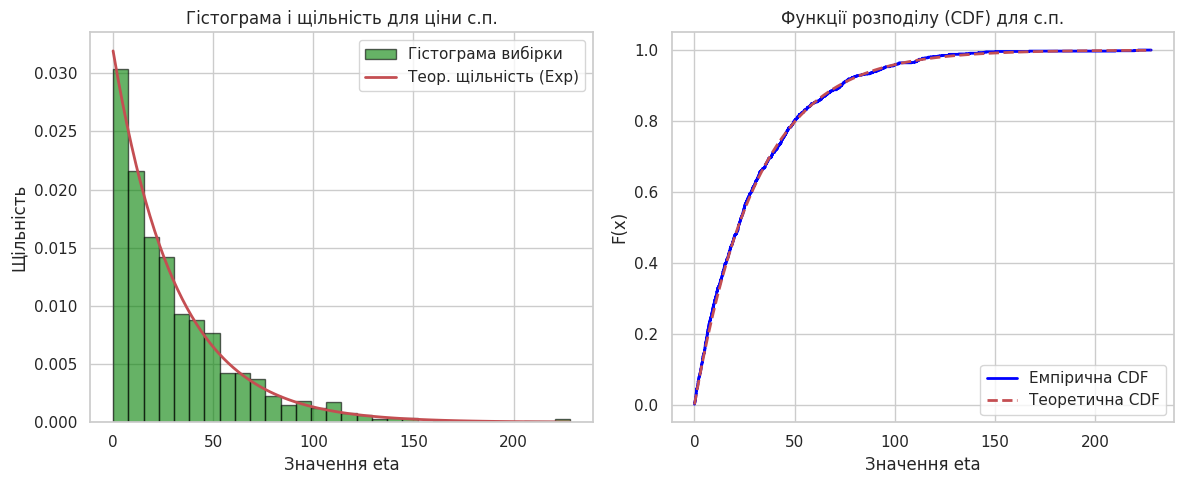

In [28]:
eta = data['special_proposition']

mean_eta = eta.mean()
std_eta = eta.std(ddof=1)
n_eta = len(eta)

t_95 = stats.t.ppf(0.975, df=n_eta-1)
t_99 = stats.t.ppf(0.995, df=n_eta-1)

sem = std_eta / np.sqrt(n_eta)
ci_eta_95 = (mean_eta - t_95 * sem, mean_eta + t_95 * sem)
ci_eta_99 = (mean_eta - t_99 * sem, mean_eta + t_99 * sem)

print(f"Середня вартість товару зі с.п. (mu): {mean_eta:.4f}")
print(f"Інтервал 95%: [{ci_eta_95[0]:.4f}, {ci_eta_95[1]:.4f}]")
print(f"Інтервал 99%: [{ci_eta_99[0]:.4f}, {ci_eta_99[1]:.4f}]\n")

lambda_k_hat = 1 / mean_eta
print(f"Оцінка параметра lambda_k: {lambda_k_hat:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(eta, bins=30, density=True, alpha=0.6, color='green', edgecolor='black', label='Гістограма вибірки')
x = np.linspace(eta.min(), eta.max(), 100)
pdf_theo = stats.expon.pdf(x, scale=1/lambda_k_hat)
plt.plot(x, pdf_theo, 'r-', lw=2, label=f'Теор. щільність (Exp)')
plt.title('Гістограма і щільність для ціни с.п.')
plt.xlabel('Значення eta')
plt.ylabel('Щільність')
plt.legend()

plt.subplot(1, 2, 2)
x_sorted = np.sort(eta)
y_ecdf = np.arange(1, len(x_sorted) + 1) / len(x_sorted)
plt.step(x_sorted, y_ecdf, label='Емпірична CDF', color='blue', lw=2)

cdf_theo = stats.expon.cdf(x, scale=1/lambda_k_hat)
plt.plot(x, cdf_theo, 'r--', lw=2, label='Теоретична CDF')
plt.title('Функції розподілу (CDF) для с.п.')
plt.xlabel('Значення eta')
plt.ylabel('F(x)')
plt.legend()

plt.tight_layout()
plt.show()

# 3. Інші товари
Тут нас цікавлять інші товари (без с.п.) та розподіл їх вартостей.
Тут $\xi_i$=$total - special\_proposition$

### Задачі:
1. Оцініть середню вартість товару без с.п. $\mu$
2. Побудуйте середньої вартості товару без с.п. $\mu$ довірчі інтервали із рівнями 95% та 99%

Припустимо, що вартість товарів без с.п. ($\xi_i$) має розподіл $Exp(\lambda)$, $\lambda$>0  
Увага! Тут припускаємо, що $\lambda$ тут і в пункті 2 - один і той же параметр, тобто  
($\eta_i$) має розподіл $Exp(\lambda k)$,  
($\xi_i$) має розподіл $Exp(\lambda)$,  
 k>0, $\lambda$>0  

### Задачі:
1. Побудуйте гістограму та еміричну функцію розподілу для ціни товарів інших товарів
2. Оцініть параметр $\lambda$ розподілу. Чи буде оцінка незміщеною? Консистентною?
3. Побудуйте теоретичну функцію розподілу, в який підставите оцінку $\lambda$

### Задача із:
1. (*) Запропонуйте оцінку для параметра $k$. Тут можна використати знання про розподіли цін товарів з та без с.п.
2. (*) за доведення консистентності, чи оцінка зміщена?

(*) означає - можна використати генеративний ШІ, але обов'язково розібрати його доведення так, щоб могли відповідати на мої питання

Середня вартість інших товарів (xi): 99.1665
Інтервал 95%: [93.1054, 105.2276]
Інтервал 99%: [91.1953, 107.1378]

Оцінка параметра lambda: 0.0101


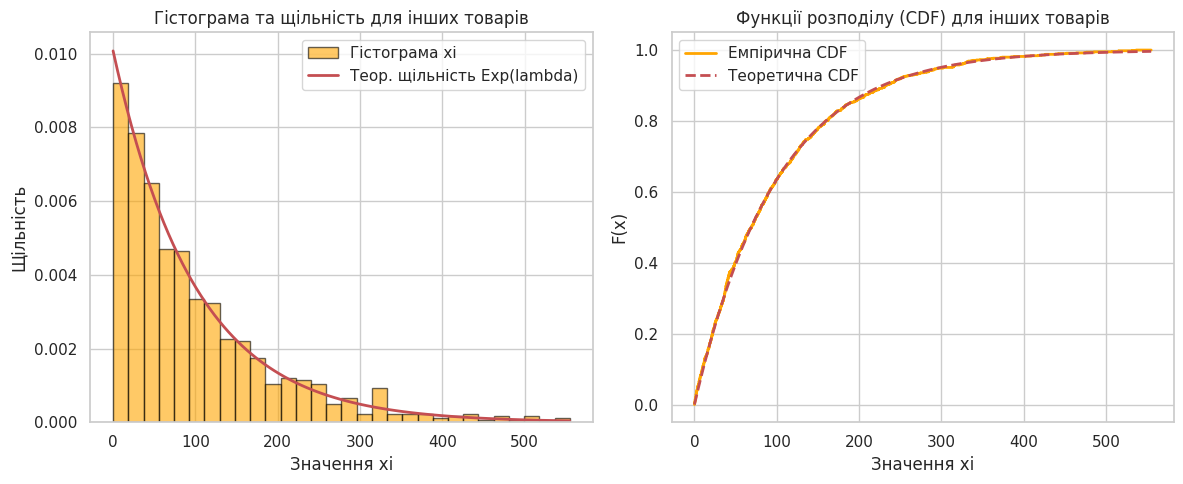

(*) Оцінка параметра k: 3.1659


In [30]:
xi = data['total'] - data['special_proposition']

mean_xi = xi.mean()
std_xi = xi.std(ddof=1)
n_xi = len(xi)

t_xi_95 = stats.t.ppf(0.975, df=n_xi-1)
t_xi_99 = stats.t.ppf(0.995, df=n_xi-1)
sem_xi = std_xi / np.sqrt(n_xi)

ci_xi_95 = (mean_xi - t_xi_95 * sem_xi, mean_xi + t_xi_95 * sem_xi)
ci_xi_99 = (mean_xi - t_xi_99 * sem_xi, mean_xi + t_xi_99 * sem_xi)

print(f"Середня вартість інших товарів (xi): {mean_xi:.4f}")
print(f"Інтервал 95%: [{ci_xi_95[0]:.4f}, {ci_xi_95[1]:.4f}]")
print(f"Інтервал 99%: [{ci_xi_99[0]:.4f}, {ci_xi_99[1]:.4f}]\n")

lambda_hat = 1 / mean_xi
print(f"Оцінка параметра lambda: {lambda_hat:.4f}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(xi, bins=30, density=True, alpha=0.6, color='orange', edgecolor='black', label='Гістограма xi')
x_xi = np.linspace(xi.min(), xi.max(), 100)
plt.plot(x_xi, stats.expon.pdf(x_xi, scale=1/lambda_hat), 'r-', lw=2, label='Теор. щільність Exp(lambda)')
plt.title('Гістограма та щільність для інших товарів')
plt.xlabel('Значення xi')
plt.ylabel('Щільність')
plt.legend()

plt.subplot(1, 2, 2)
x_xi_sorted = np.sort(xi)
y_xi_ecdf = np.arange(1, len(x_xi_sorted) + 1) / len(x_xi_sorted)
plt.step(x_xi_sorted, y_xi_ecdf, label='Емпірична CDF', color='orange', lw=2)
plt.plot(x_xi, stats.expon.cdf(x_xi, scale=1/lambda_hat), 'r--', lw=2, label='Теоретична CDF')
plt.title('Функції розподілу (CDF) для інших товарів')
plt.xlabel('Значення xi')
plt.ylabel('F(x)')
plt.legend()

plt.tight_layout()
plt.show()

k_hat = mean_xi / mean_eta
print(f"(*) Оцінка параметра k: {k_hat:.4f}")

# 4. Доля с.п. у замовлені

В цьому розділі нас цікавить частка товарів з с.п. у замовленні. Тобто, величини $\frac{\eta_i}{\xi_i+\eta_i}$. Можливо, вони якось пов'язані із поверненнями.
Чи залежать поверення від частки акційних товарів? Доведіть! (побудуйте аналітику!)

У припущенні, що ($\eta_i$) має розподіл $Exp(\lambda k)$,  та ($\xi_i$) має розподіл $Exp(\lambda)$

## Задачі по варіантам:

1. Чи можливо лише по вибірці з $\frac{\eta_i}{\xi_i+\eta_i}$ оцінити параметри $\lambda$ та $k$?
2. Чи можливо лише по вибірці з $\frac{\xi_i}{\xi_i+\eta_i}$ оцінити параметри $\lambda$ та $k$?
3. Чи можливо лише по вибірці з $\frac{\xi_i}{\eta_i}$ оцінити параметри $\lambda$ та $k$?
4. Чи можливо лише по вибірці з $\xi_i + \eta_i$ оцінити параметри $\lambda$ та $k$?
5. Чи можливо лише по вибірці з $\xi_i - \eta_i$ оцінити параметри $\lambda$ та $k$?
6. Чи можливо лише по вибірці з $1/  (\xi_i + \eta_i)$ оцінити параметри $\lambda$ та $k$?

Варіант 6
--------------------------------------
Характеристики вибірки 1 / (xi + eta):
Середнє: 0.0165
Медіана: 0.0095
Стандартне відхилення: 0.0218


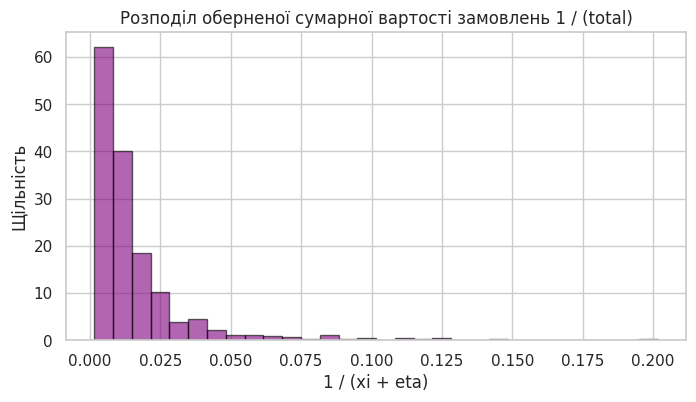

In [36]:
total_cost = data['total']
inverse_total = 1 / total_cost

print("Варіант 6")
print("--------------------------------------")
print("Характеристики вибірки 1 / (xi + eta):")
print(f"Середнє: {inverse_total.mean():.4f}")
print(f"Медіана: {inverse_total.median():.4f}")
print(f"Стандартне відхилення: {inverse_total.std(ddof=1):.4f}")

plt.figure(figsize=(8, 4))
plt.hist(inverse_total, bins=30, density=True, alpha=0.6, color='purple', edgecolor='black')
plt.title("Розподіл оберненої сумарної вартості замовлень 1 / (total)")
plt.xlabel("1 / (xi + eta)")
plt.ylabel("Щільність")
plt.show()